# Sensitivity of the (E, P) inversion to the fixed ice/water parameters

One 30-min covariance block (2025-05-06 00:00 UTC), inverted with $\nu$, $h_w$, $\rho_i$ and $\rho_w$
each swept **one at a time** around the baseline, by `scripts/bf_inv_disp/diag_sensitivity_ice_params.py`.
Each `sensitivity_<param>.npz` holds one parameter's sweep, baseline included, sorted by value.

Reads `outputs/bf_inv_disp/sensitivity/` (`sensitivity_<param>.npz` and `config.json`) and writes the
PDFs to `figures/` next to this notebook.

Note that the MAP values here do not match those reported in the manuscript. These are the estimates of this
one block (baseline: $E$ = 0.6 GPa, $P$ = 0.7 MPa), whereas the manuscript's MAP comes from the posterior
marginalized over the whole time series (598 blocks, `posterior_stacked_EP.npz`, Fig. 7: $E$ = 0.6 GPa,
$P$ = 0.6 MPa). The figure shows how much each fixed parameter moves the estimate, not the estimate itself.

In [1]:
import json

import numpy as np
import pandas as pd
import matplotlib as mpl
import matplotlib.pyplot as plt

from das_tools.utils import proj_path

plt.rcParams.update({
    "font.size": 16,          # base size
    "axes.titlesize": 18,
    "axes.labelsize": 16,
    "xtick.labelsize": 14,
    "ytick.labelsize": 14,
    "legend.fontsize": 16,
})
mpl.rcParams.update({
    "text.usetex": True,
    "font.family": "serif",
    "text.latex.preamble": r"\usepackage{amsmath}\usepackage{amssymb}\usepackage{times}",
})

SENS_DIR = proj_path.output_dir("bf_inv_disp", "sensitivity")
FIG_DIR = proj_path.figures_dir("supplementary", "S7_fg_inv_sensitivity", "figures")
FIG_DIR.mkdir(parents=True, exist_ok=True)

# Panel order (a)-(d): parameter -> (name, LaTeX symbol, unit)
PARAMS = {
    "nu":    ("Poisson's ratio", r"\nu",    ""),
    "h_w":   ("Water depth",     r"h_w",    "m"),
    "rho_i": ("Ice density",     r"\rho_i", "kg/m$^3$"),
    "rho_w": ("Water density",   r"\rho_w", "kg/m$^3$"),
}

# Which MAP to plot:
#   "EP"    -- mode of p(E, P) with direction integrated out
#   "joint" -- (E, P) of the joint MAP over (E, P, theta), as step 3 reports it
MAP_KIND = "EP"

SHOW_CI = False     # shade the 5-95 % marginal interval of E and P (axis ranges ignore it)
SHARE_Y = True      # same E and P ranges in every panel, so sensitivities compare by eye

# Same palette as the hammer sensitivity figure (Fig. S6, notebooks/tap_inv_batch/invert_sensitivity_test.ipynb)
E_COLOR, P_COLOR, INK = "#2a78d6", "#e07b28", "#52514e"


def x_label(p):
    _, sym, unit = PARAMS[p]
    return f"${sym}$ [{unit}]" if unit else f"${sym}$"

In [2]:
config = json.loads((SENS_DIR / "config.json").read_text())
sens = {p: dict(np.load(SENS_DIR / f"sensitivity_{p}.npz")) for p in PARAMS}
ref = next(iter(sens.values()))
b_ref = ref["is_baseline"]

key_E, key_P = ("E_map_EP", "P_map_EP") if MAP_KIND == "EP" else ("E_map", "P_map")
E_gpa = ref["E_all"] / 1e9
P_mpa = ref["C_all"] / 1e6
dE, dP = np.median(np.diff(E_gpa)), np.median(np.diff(P_mpa))
f_used = ref["freq_used"]

## Four-panel figure: MAP of $E$ and $P$ against the value of each parameter

Same look as the hammer sensitivity figure (Fig. S6). The x-axis is the swept parameter and the y-axes
are the MAP estimates, both in their own units. The dashed vertical line is the fixed value used in the
production inversion; the dashed horizontal lines (blue for $E$, orange for $P$) are this block's
baseline MAP. $E$ is on the left axis, $P$ on the right. The MAP lives on the
$(E, P)$ grid, so it moves in steps of the grid spacing.

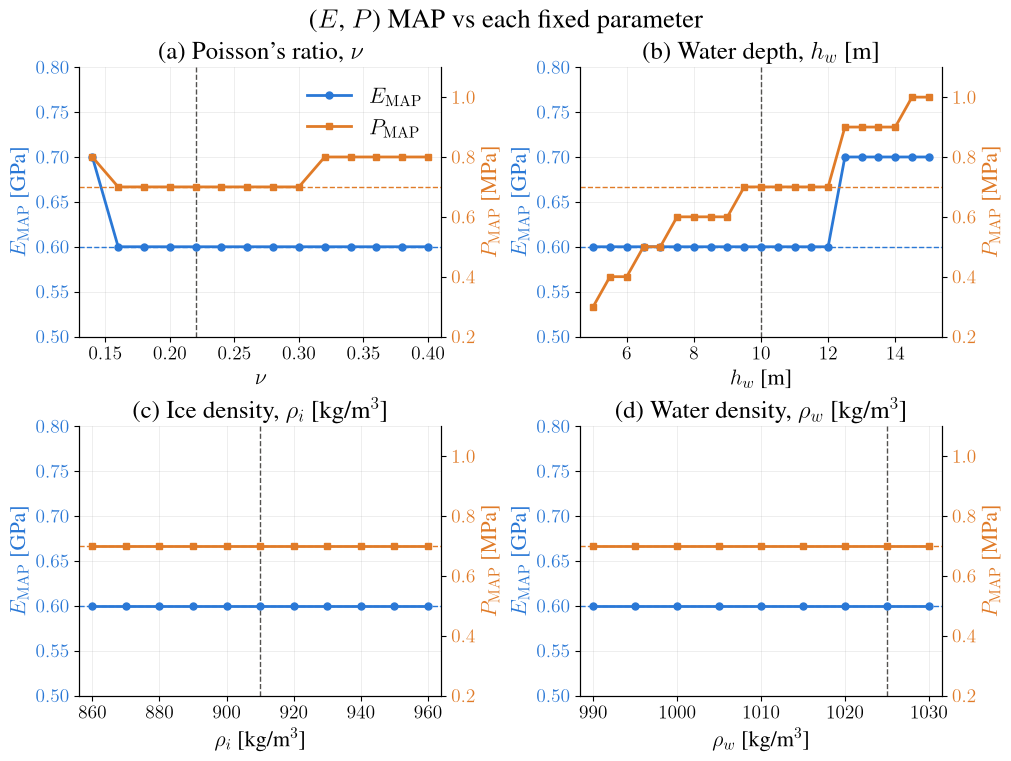

In [3]:
def style(ax, grid=True):
    if grid:
        ax.grid(alpha=0.3, lw=0.5)
    ax.spines["top"].set_visible(False)


def padded_range(vals, step):
    return np.nanmin(vals) - step, np.nanmax(vals) + step


# This block's baseline MAP, which every sweep shares (asserted above).
E_rep = ref[key_E][b_ref][0] / 1e9
P_rep = ref[key_P][b_ref][0] / 1e6

E_map = {p: d[key_E] / 1e9 for p, d in sens.items()}
P_map = {p: d[key_P] / 1e6 for p, d in sens.items()}

# Ranges from the MAPs alone: a single block's 5-95 % interval can span most of
# the grid and would flatten the lines if it set the scale.
E_lim = padded_range(np.concatenate(list(E_map.values())), dE)
P_lim = padded_range(np.concatenate(list(P_map.values())), dP)

fig, axes = plt.subplots(2, 2, figsize=(10, 7.5), constrained_layout=True)

for i, (p, ax) in enumerate(zip(PARAMS, axes.flat)):
    d = sens[p]
    x = d["values"]
    axP = ax.twinx()

    if SHOW_CI:
        ax.fill_between(x, d["E_p05"] / 1e9, d["E_p95"] / 1e9, color=E_COLOR, alpha=0.18, lw=0)
        axP.fill_between(x, d["P_p05"] / 1e6, d["P_p95"] / 1e6, color=P_COLOR, alpha=0.18, lw=0)

    ax.axvline(float(d["baseline_value"]), color=INK, ls="--", lw=1)
    ax.axhline(E_rep, color=E_COLOR, ls="--", lw=1)
    axP.axhline(P_rep, color=P_COLOR, ls="--", lw=1)
    lE, = ax.plot(x, E_map[p], color=E_COLOR, lw=2, marker="o", ms=5, label=r"$E_\mathrm{MAP}$")
    lP, = axP.plot(x, P_map[p], color=P_COLOR, lw=2, marker="s", ms=5, label=r"$P_\mathrm{MAP}$")

    ax.set_title(f"({'abcd'[i]}) {PARAMS[p][0]}, {x_label(p)}")
    ax.set_xlabel(x_label(p))
    ax.set_ylabel(r"$E_\mathrm{MAP}$ [GPa]", color=E_COLOR)
    axP.set_ylabel(r"$P_\mathrm{MAP}$ [MPa]", color=P_COLOR)
    ax.tick_params(axis="y", labelcolor=E_COLOR)
    axP.tick_params(axis="y", labelcolor=P_COLOR)
    if SHARE_Y:
        ax.set_ylim(*E_lim)
        axP.set_ylim(*P_lim)
    pad = 0.04 * (x.max() - x.min())
    ax.set_xlim(x.min() - pad, x.max() + pad)
    style(ax)
    style(axP, grid=False)    # the two y-axes' ticks don't line up

axes[0, 0].legend(handles=[lE, lP], loc="best", frameon=False)
fig.suptitle("($E$, $P$) MAP vs each fixed parameter")

fig.savefig(FIG_DIR / f"sensitivity_EP_map_{MAP_KIND}.pdf")
plt.show()